# Gemma's BFS-vs-DFS fork: the iteration-7 pipeline (`method.py`), runnable on CPU

**Artifact `art_HY7uYZz-OjRW`** · *Circuit and dose dial at Gemma's BFS-vs-DFS fork* · model `google/gemma-3-4b-it` (bf16)

**The question.** Asked to write `solve(grid, start, goal)` (a path on a grid), Gemma-3-4B-it almost always opens with the same 32 tokens c\*: ```` ```python ````, `def solve(grid, start, goal):`, `rows = len(grid)`, `cols = len(grid[0])` and an indent. The next token (response index 32) decides the algorithm. ` visited` leads to **depth-first search (DFS)**. A blank line, `if`, `queue` or `q` lead to **breadth-first search (BFS)**. Iteration 7 studies this one fork:
- **G1**: which heads and MLPs compute the fork margin m = logsumexp(z[B]) - z['visited'] (path patching, then ablation and steering in the real model);
- **G2**: whether a low-rank DAS subspace at the fork works as a *dose dial* for the algorithm;
- **G3**: whether temperature acts only through this fork margin. The run's answer is yes. At low temperature the model has one idea (DFS); raising the temperature only moves probability across the fork it already has and adds no new algorithm: none of the 2,325 correct programs in all arms was labelled 'other', i.e. outside the catalogue of known path-search algorithms.

**What `method.py` is.** It is the artifact's entry point: one function per stage, run as `python method.py --stage s0 | engine | label | g3a | g3b | yv | g1p | g1v | g2 | g2r | g2d | novelty | analysis | figures | outputs`, plus the pre-registered decision rules. The file defines three stages itself and hands the rest to modules in `src/`:
- **S0**: CPU unit tests, a GPU batch-shape test, commitment #0;
- **engine**: GPU unit tests, engine check, U6, G3-cal;
- **label**: the CPU label worker.

**What this notebook runs (CPU only).**

| Part of `method.py` | In this notebook |
|---|---|
| S0: inputs manifest, labeller on the 12 reference programs, checker mutants, token ids and c\*, CRN streams, DAS toy, instrument ids, commitment #0 | **runs** |
| S0: GPU batch-shape time test | code shown; its selection rule is re-applied to the recorded GPU timings |
| `engine` stage (Gemma-3-4B on a 16 GB GPU: U1-U4, engine check, U6, G3-cal) | code shown; its 50 engine-check generations are this demo's dataset |
| `label` stage: frozen exp8 labeller (hidden tests, runtime tracer, AST rules; LLM judge when they disagree) | **runs** on the 50 recorded generations, with the judge's answers replayed from the run's cache |
| `ENGINE_CHECK` decision (from `src/analysis7.py`) | **runs** |

`mini_demo_data.json` holds:
- the 50 engine-check generations (5 twin templates x 10 CRN slots) with the labels the run gave them;
- iteration 6's rows for the same slots;
- the frozen labeller suite, byte-identical and checked against iteration 6's sha256 manifest;
- the small JSON results the GPU stages recorded.

The analysis takes about a minute on 2 CPUs once the packages are installed.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (the artifact's logger; the frozen labeller harness imports it too)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib, huggingface_hub, tokenizers, transformers, torch -- pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0', 'huggingface_hub==1.4.0', 'tokenizers==0.22.2',
         'transformers==5.0.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# ---- method.py's import block
import argparse
import json
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- further imports used by the helpers copied from src/ (cfg, label_worker, engine, g2, commit, analysis7)
import hashlib
import math
import os
import re
import resource
import threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from typing import Iterable

import numpy as np
import torch

# ---- notebook only: a temporary run folder, tables and plots
import tempfile

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/experiment-38/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["about"]["artifact"])
print("model:", data["about"]["model"])
print(f"dataset: {data['dataset']} -- {len(data['examples'])} generations | {len(data['frozen_code'])} vendored files | "
      f"recorded results: {', '.join(sorted(data['recorded']))}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_HY7uYZz-OjRW (iteration 7, experiment 38): circuit and dose dial at Gemma's BFS-vs-DFS fork, google/gemma-3-4b-it
model: google/gemma-3-4b-it@093f9f388b31de276ce2de164bdc2081324b9767 (bf16)
dataset: engine_check -- 50 generations | 28 vendored files | recorded results: commit0, das_toy, engine_check, g3_cal, s0_tests, tests_gpu_s1, u6


## Configuration

All tunable sizes are set here; each comment gives the original value from `method.py` / `src/`. `RUN_DIR` is a fresh temporary folder that stands in for the artifact folder (`ROOT` in `src/cfg.py`). The vendored inputs are written there, and every stage writes its outputs there (`data/`, `results/`, `predictions/`, `logs/`).

In [5]:
# All values below are the original ones of method.py / src/ (they fit in a few minutes on 2 CPUs).
# Quick smoke test: N_ENGINE_ROWS = 2, N_REFERENCES = 2, N_MUTANTS = 1, CRN_N = 16 and 2 steps for each TOY_* run.
N_ENGINE_ROWS = 50       # engine-check generations to label (original: all 50 = 5 twin templates x 10 CRN slots)
N_REFERENCES = 12        # T1 reference programs run through the labeller in S0 (original: all 12)
N_MUTANTS = 5            # hand-made wrong programs the hidden tests must reject (original: all 5)
CRN_N = 2048             # length of the uniform CRN stream compared for bit-identity (original: 2048)
# DAS toy (src/g2.py toy_test): (n_train, lr, steps, batch) of its runs
TOY_DAS = (4096, 2e-2, 800, 512)    # original: run(4096, 2e-2, 800, 512) -- DAS, and SHUF with shuffled targets
TOY_PLAN = (4096, 2e-3, 400, 64)    # original: run(4096, 2e-3, 400, 64)  -- the plan's optimiser setting
TOY_SMALL = (256, 2e-2, 300, 256)   # original: run(256, 2e-2, 300, 256)  -- small-n overfit
N_WORKERS = 5            # label-worker threads (original: src/label_worker.py N_WORKERS = 5)
LIST_INSTRUMENTS = True  # S0 instrument ids: query the Hugging Face Hub (set False when offline)
# the run loaded google/gemma-3-4b-it @ IT_REV (gated: needs a Hugging Face token with the Gemma licence accepted);
# unsloth/gemma-3-4b-it is a public copy of the same tokenizer files -- the S0 token checks verify the ids
TOKENIZER_REPO = "unsloth/gemma-3-4b-it"

RUN_DIR = Path(tempfile.mkdtemp(prefix="gemma_fork_demo_"))     # stands in for the artifact folder (cfg.ROOT)
print("RUN_DIR =", RUN_DIR)

RUN_DIR = /tmp/gemma_fork_demo_czuudq8g


## Shared constants (`src/cfg.py`)

`method.py` begins with `sys.path.insert(0, ROOT / "src")` and `from cfg import (...)`. The constants below are copied verbatim from `src/cfg.py`; the one change is that `ROOT` is `RUN_DIR`. They define the experiment:
- the five **twin templates** W1-W5, e.g. `"Do not use {X} for this task."` with a neutral noun such as *house* for X. The twin has the same token length as the ban of DFS but bans nothing;
- the forced templates F1-F5 (`"Use {Y} for this task."`) with four BFS/DFS display-name pairs of equal token length;
- the fork's token classes **B** = {`\n`, `if`, `queue`, `q`} (BFS) and **D** = {`visited`} (DFS), at response index 32;
- the DAS layers, ranks and seeds, the doses of the G2 dose sweep and the temperatures and samplers of G3.

In [6]:
ROOT = RUN_DIR                                  # cfg.py: Path(__file__).resolve().parents[1] (the artifact folder)
I6 = ROOT / "inputs" / "iter6_gemma"            # read-only copy of the iteration-6 Gemma artifact (MANIFEST.sha256)
INPUTS = I6 / "inputs"
E8 = INPUTS / "exp8"
E11 = INPUTS / "exp11"
E7 = INPUTS / "exp7"
E9 = INPUTS / "exp9"
E23 = INPUTS / "exp23"
DEP1 = INPUTS / "art_j3Rm_lr2nzR6"
DEP_EXTRACT = INPUTS / "dep_extract"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
I6_RESULTS = I6 / "results"
I6_DATA = I6 / "data"
DATA_DIR = ROOT / "data"
CACHE_DIR = ROOT / "cache"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
AUDIT_DIR = ROOT / "audit"
STATES_DIR = CACHE_DIR / "states"
SUBSPACE_DIR = CACHE_DIR / "das_subspaces"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR, AUDIT_DIR, STATES_DIR, SUBSPACE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
COMMIT_LOG = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ models
IT_ID = "google/gemma-3-4b-it"
IT_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
MODELS = {"it": (IT_ID, IT_REV)}
N_LAYERS = 34
D_MODEL = 2560
N_HEADS = 8
HEAD_DIM = 256
CAPTURE_BLOCKS = list(range(11, 34))
BOS_ID = 2
EOS_ID = 1
SOT_ID = 105
EOT_ID = 106
STOP_IDS = {"it": (EOS_ID, EOT_ID)}
CHAT_HEAD = "<bos><start_of_turn>user\n"
CHAT_TAIL = "<end_of_turn>\n<start_of_turn>model\n"
MAX_NEW = 1024                         # natural T1 programs: median 315, max 413 tokens (iteration 6, n = 200)
MAX_NEW_PATH = MAX_NEW
MAX_NEW_BENCH = MAX_NEW
STOP_CHECK_EVERY = 16
PRECISION = "bf16 (sdpa attention); logits fp32, CDF float64"
TC_REPO = "mwhanna/gemma-scope-2-4b-it"
TC_REV = "61cb16ec74f348f4a8643fe3a0157be9dc8a851d"
TC_SUB = "transcoder_all/width_16k_l0_big_affine"
TC_SUB_SMALL = "transcoder_all/width_16k_l0_small_affine"
SCOPE_REPO = "google/gemma-scope-2-4b-it"
CT_COMMIT = "255d989e93be1299d53d67b59e9fd76a0e274b14"   # safety-research/circuit-tracer HEAD on 2026-10-22

# ------------------------------------------------------------------------------------------------ tasks (T1 only)
PATH_TASKS = ("T1", "T2")
EXP8_TASK = {"T1": "t1", "T2": "t2"}
EXP23_TWIN_X = {"T1": "dfs", "T2": "dijkstra"}
TEMPLATES: dict[str, tuple[str, str]] = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")
FORCED_TEMPLATES = {
    "F1": "Use {Y} for this task.",
    "F2": "Your solution must rely on {Y}.",
    "F3": "Use {Y} throughout.",
    "F4": "{Y} is required here.",
    "F5": "Write a correct solution that uses {Y}.",
}
TRAIN_F = ("F1", "F2", "F3")
HELD_F = ("F4", "F5")
# display-name pairs (BFS, DFS) with equal Gemma token counts within each pair (asserted at S0)
DISPLAY_PAIRS = (("BFS", "DFS"),
                 ("breadth-first search", "depth-first search"),
                 ("a breadth-first search", "a depth-first search"),
                 ("breadth-first search (BFS)", "depth-first search (DFS)"))
PAD_FILLER = " ."
MAX_PAD = 24
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
PLAIN_STDLIB = "Use only the Python standard library."
T1_MODES = ("bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra")
NOT_COUNTED = ("invalid", "disputed")
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
OPENROUTER_CAP_USD = 0.50

# ------------------------------------------------------------------------------------------------ design (iteration 7)
SLOT_PREFIX_OLD = "iter5E"             # iteration 6's slot_key for slots 0-9 (engine check reproduces these keys)
SLOT_PREFIX_I6 = "iter6S"
SLOT_PREFIX = "iter7G"
N_OLD_SLOTS = 10
FORK_INDEX = 32
B_IDS = (107, 584, 15204, 236809)
D_IDS = (53227,)
B_STRS = ("\n", "if", "queue", "q")
D_STRS = ("visited",)
I6_NATURAL = {"k": 61, "n": 200, "ci95": (0.245, 0.372)}
DAS_LAYERS_SCAN = (17, 19, 21, 22, 23, 25, 27, 29)
DAS_LAYER_FIXED = 22
DAS_RANKS = (1, 2, 4, 8)
DAS_SEEDS = (0, 1, 2)
DAS_STEPS = 400
DAS_LR = 2e-2                          # plan: 2e-3; the toy shows 2e-3 x 400 steps does not move the subspace
DAS_BATCH = 48                         # plan: 64; 48 fits the 16 GB GPU with the base KV stacks
DOSES = (0.1, 0.2, 0.35, 0.5, 0.75, 1.0)
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = ("topp1", "topk10")
TOPK = 10

The small helpers from `src/cfg.py` that the stages below use, copied verbatim:
- logging;
- deterministic seeds and the **CRN slot keys** (`stable_seed`, `slot_key_i6`, `slot_key7`);
- JSON/JSONL I/O, which turns NaN/inf into `null`;
- the Wilson interval used by the decision rules;
- `bench_paths`, which puts the frozen suites on `sys.path`.

In [7]:
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, math.ceil(int(parts[0]) / int(parts[1])))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp23 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def slot_key_i6(task: str, w: str, k: int) -> tuple[str, str, str, int]:
    """Iteration 6's slot_key (method.py): 'iter5E' for slots 0-9, 'iter6S' otherwise."""
    return (SLOT_PREFIX_OLD if k < N_OLD_SLOTS else SLOT_PREFIX_I6, task, w, k)


def slot_key7(part: str, w: str, k: int) -> tuple[str, str, str, int]:
    return (SLOT_PREFIX + part, "T1", w, k)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        lines = fh.readlines()
    for i, line in enumerate(lines):
        line = line.strip()
        if not line:
            continue
        try:
            out.append(json.loads(line))
        except json.JSONDecodeError:
            if i == len(lines) - 1:
                continue
            logger.warning(f"skipping malformed line {i} in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> int:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    n = 0
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
            n += 1
        fh.flush()
    return n


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def add_deviation(key: str, text: str) -> None:
    p = RESULTS_DIR / "deviations.json"
    d = read_json(p) if p.exists() else {}
    d[key] = text
    write_json(p, d)


def bench_paths() -> None:
    for p in (str(SUITE), str(E11)):
        if p not in sys.path:
            sys.path.insert(0, p)

## Inputs: write the vendored files into `RUN_DIR`

The original stages read three kinds of files. They are carried in `mini_demo_data.json` and written here to the same relative paths:
1. **Iteration 6's vendored code** (`inputs/iter6_gemma/`), which is the frozen exp8 labeller suite:
   - the hidden tests for the grid task (`tests.json`, 48 cases) and their per-case time limits;
   - the 12 reference programs;
   - the sandbox runner, the runtime tracer and the AST rules.

   Two more files go with it: exp11's `extract_code` and this artifact's `src/regate_rules.py`, which the label worker imports and which only acts on task T2. `MANIFEST.sha256` gets iteration 6's hash lines for exactly these files.
2. **The engine stage's raw generations** (`data/raw_engine.jsonl`): the first `N_ENGINE_ROWS` of the 50 engine-check rows, each with its template, CRN slot key, generated text and token ids.
3. **Iteration 6's rows for the same CRN slots** (`inputs/iter6_gemma/data/labels.jsonl` and `raw_s3.jsonl`), and the run's **cached judge verdicts** (`data/judge_cache_paths.jsonl`).

In [8]:
# 1. iteration 6's vendored code and this artifact's src/regate_rules.py, at their paths inside the artifact
for rel_path, text in data["frozen_code"].items():
    p = ROOT / rel_path
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding="utf-8")
(I6 / "MANIFEST.sha256").write_text("\n".join(data["manifest"]) + "\n")    # iteration 6's lines for these files
sys.path.insert(0, str(ROOT / "src"))                                     # as method.py: sys.path.insert(0, ROOT / "src")
bench_paths()                                                             # the frozen suites (SUITE, E11) on sys.path

# 2. the engine stage's raw generations (data/raw_engine.jsonl): the demo dataset
rows_demo = data["examples"][:N_ENGINE_ROWS]
(DATA_DIR / "raw_engine.jsonl").write_text("".join(json.dumps(e["raw"]) + "\n" for e in rows_demo))

# 3. iteration 6's rows for the same CRN slots (label and token ids), and the run's cached judge verdicts
I6_DATA.mkdir(parents=True, exist_ok=True)
(I6_DATA / "labels.jsonl").write_text("".join(
    json.dumps({k: e["iter6"][k] for k in ("row_id", "label", "passed")}) + "\n" for e in rows_demo))
(I6_DATA / "raw_s3.jsonl").write_text("".join(
    json.dumps({k: e["iter6"][k] for k in ("row_id", "token_ids")}) + "\n" for e in rows_demo))
(DATA_DIR / "judge_cache_paths.jsonl").write_text("".join(json.dumps(r) + "\n" for r in data["judge_cache"]))

print(f"wrote {len(data['frozen_code'])} vendored files, {len(rows_demo)} raw generations, {len(rows_demo)} iteration-6 "
      f"rows and {len(data['judge_cache'])} cached judge verdicts under {RUN_DIR}\n")
print(f"one generation ({rows_demo[0]['raw']['row_id']}, CRN key {rows_demo[0]['raw']['ukey']}) -- the prompt:\n")
print(rows_demo[0]["prompt"])
print("\n-- and Gemma's response:\n")
print(rows_demo[0]["raw"]["text"])

wrote 28 vendored files, 50 raw generations, 50 iteration-6 rows and 3 cached judge verdicts under /tmp/gemma_fork_demo_czuudq8g

one generation (engine|W1|0, CRN key ['iter5E', 'T1', 'W1', 0]) -- the prompt:

Do not use house for this task. . . . . . .

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, or start or goal is a 

## Pre-registered decision rules (`method.py`)

`method.py` fixes three things in advance: its decision rules, the order in which parts may be dropped if the GPU budget runs out, and the parts that may never be dropped. All three go into commitment #0 at the end of S0, **before** any decisive sample is drawn. This notebook evaluates `ENGINE_CHECK`; the G1, G2 and G3 rules need the GPU stages. `GPU_STAGES` lists the stages that `main()` does not run under the 12 GB address-space cap.

In [9]:
GPU_STAGES = ("s0", "engine", "g3a", "g3b", "yv", "g1p", "g1v", "g2", "g2r", "g2d", "g2smoke", "g1gen", "g2pairs")

DECISION_RULES = {
    "ENGINE_CHECK": "Pass if the twin BFS share (N=50, natural sampling T=1 top-p 1) lies inside iteration 6's Wilson "
                    "95% CI [0.245, 0.372] for 61/200; per-slot label agreement with iteration 6's rows is reported "
                    "whatever it is.",
    "U6": "200 continuations from the empty response prefix: (a) fork-resampling path (multi-prompt batches, partial "
          "labeller; also labelled with the full labeller) and (b) the main single-prompt fixed-shape engine; each is "
          "compared with the natural share (two-proportion exact test). Diagnosis: labeller (a-partial vs a-full), "
          "batching ((a) vs (b)), or neither.",
    "G3_SOURCE_RULE": "PRIMARY P(BFS | t) for t in B and D is iteration 6's token table UNLESS the U6 diagnosis shows "
                      "that path (a) differs from (b) at p < 0.05; then the primary is the G3-cal estimate. The other "
                      "source is reported as the sensitivity.",
    "NODE_CLAIM": "Holm p < 0.05 (exact one-sided sign-flip permutation over the 20 variant prompts, Holm over the "
                  "top 10) AND the median d_i is in the expected direction AND joint top-5 beats >= 95% of its random "
                  "sets on the median over prompts.",
    "G2_DAS_REAL": "At some k <= 8 (seed median), DAS recovery - RAND recovery >= 0.4 (paired Wilcoxon over held-out "
                   "pairs, p < 0.01) AND SHUF held-out recovery <= 0.1 AND RINIT held-out effect < 0.5 x the trained "
                   "model's effect in nats.",
    "SMALLEST_SUFFICIENT_RANK": "the smallest k with recovery >= 0.8.",
    "ONE_DIMENSIONAL_WORDING": "only if k=1 recovery >= 0.8 AND Spearman(R_1^T h_v, y_v) >= 0.5 (p < 0.01) AND "
                               "G2-KNOB holds; otherwise 'a rank-k subspace carries the forced-prompt transfer'.",
    "DORMANT_FLAG": "share_k at or below the 95th percentile of random AND |Spearman| < 0.2.",
    "K_STAR": "the smallest k whose train-CV recovery >= 0.9 x the maximum over k.",
    "G2_KNOB": "some BFS-direction dose has correct-BFS > the twin's (exact one-sided McNemar on CRN pairs, Holm over "
               "the 6 doses of that method, p < 0.05) AND pass >= 0.8 x the twin's pass; evaluated for DAS and DiM "
               "separately.",
    "G3_CONC": "pooled H(label | fork class) <= 0.3 bits.",
    "G3_LAW": "|pred - obs| <= 0.10 in every top-p-1 cell (top-k cells reported separately).",
    "G3_DISCONFIRMED": "H > 0.5 bits or any top-p-1 cell misses by more than 0.2.",
    "G3_MAE": "MAE <= 0.10 per cell.",
}
DROP_ORDER = ["G1 generation beyond 5 nodes (top-10 and DFS arms)", "the random-init control at the second layer",
              "G3 top-k at T0.7", "G2-N", "G2-L", "G3 top-k T1.3",
              "the DFS-direction DiM cells (keep DAS toward DFS at 0.2 / 0.5 / 1)"]
NEVER_DROP = ["G1 (graph or G1-P) validated in the real model on the teacher-forced margin",
              "G2 with RAND, SHUF, RINIT at L*, held-out templates, the natural-variance check and the BFS-direction "
              "dose sweep for DAS and DiM", "G3 at top-p 1 with its committed predictions", "the novelty audit",
              "the engine check and U6"]

print(f"{len(DECISION_RULES)} decision rules, {len(DROP_ORDER)} droppable parts, {len(NEVER_DROP)} never-drop parts")
print("ENGINE_CHECK:", DECISION_RULES["ENGINE_CHECK"])

14 decision rules, 7 droppable parts, 5 never-drop parts
ENGINE_CHECK: Pass if the twin BFS share (N=50, natural sampling T=1 top-p 1) lies inside iteration 6's Wilson 95% CI [0.245, 0.372] for 61/200; per-slot label agreement with iteration 6's rows is reported whatever it is.


## The label worker (`src/label_worker.py`)

Every generated program is labelled by the **frozen exp8 labeller**, which has not been edited since iteration 6's gate:
1. **extract** the first fenced block that defines `solve` (`extract5`);
2. **run** it in a stdlib-only sandbox subprocess (`python -I -S`) on the 48 hidden test cases, which gives `passed`;
3. **trace** it once more under a runtime tracer that instruments `deque`, `heapq`, `list.pop`, recursion depth and the grid's cell-access order (`_path_mech`, which calls `tasks.harness.evaluate_program`);
4. map the trace to a **runtime label** and the source code to an **AST label** (bfs, dfs, bibfs, iddfs, astar_gbfs, dijkstra, other);
5. if the two labels agree, that is the label. Otherwise a **blind LLM judge** (`openai/gpt-4.1-mini` on OpenRouter) decides (`label_path_rows`).

The code is copied verbatim except for two changes:
- **The judge call.** The frozen judge (`labeller/judge.py`) needs an OpenRouter key and `asyncio.run`, which cannot run inside a notebook's event loop. `judge_many_cached` instead replays the run's **own cached verdicts**, looked up with the judge's cache key (`model|task|sha256(code)`). A cache miss leaves the row `disputed`, as an unavailable judge does in the original.
- **Bench tasks.** The 13 exp11 bench tasks (`label_bench_rows`) are not used in iteration 7, so they are left out.

In [10]:
from regate_rules import apply_t2          # src/regate_rules.py (written to RUN_DIR/src above; acts on T2 only)

LABELS = DATA_DIR / "labels.jsonl"
EVAL_CACHE: dict[str, dict[str, Any]] = {}
_LOCK = threading.Lock()
# N_WORKERS (label_worker.py: 5) is set in the configuration cell
BENCH_JUDGE_CAP = 0.60
PATH_JUDGE_CAP = 0.40
BLOCK_RE = re.compile(r"```[^\n`]*\n(.*?)(?:\n[ \t]*```|\Z)", re.S)
SOLVE_RE = re.compile(r"\bdef solve\s*\(")
PLAIN_KEEP = ("def ", "class ", "import ", "from ", "@", "#")


def raw_files() -> list[Path]:
    return sorted(DATA_DIR.glob("raw_*.jsonl"))


# ------------------------------------------------------------------------------------------------ extraction
def cut_plain(text: str) -> str:
    lines = text.split("\n")
    out = []
    body_seen = False
    for ln in lines:
        if ln.strip() and ln[0] not in (" ", "\t"):
            if ln.startswith("if __name__") or (body_seen and not ln.startswith(PLAIN_KEEP)):
                break
        elif ln.strip():
            body_seen = True
        out.append(ln)
    return "\n".join(out).rstrip() + "\n"


def extract5(r: dict[str, Any]) -> tuple[str | None, str]:
    text = r.get("text") or ""
    if r.get("arm") == "pt_plain":
        return (r.get("program_prefix") or "") + cut_plain(text), "plain_completion"
    for m in BLOCK_RE.finditer(text):
        b = m.group(1)
        if SOLVE_RE.search(b) and b.strip():
            return b.rstrip() + "\n", "fenced_solve"
    from bench.common.harness import extract_code as bench_extract

    c = bench_extract(text)
    if c and c.strip():
        return c.rstrip() + "\n", "bench_python_block"
    from labeller.extract import extract_code as suite_extract

    c2, how = suite_extract(text)
    if c2:
        return c2, f"suite_{how}"
    return None, "no_code"


# ------------------------------------------------------------------------------------------------ path tasks
def _path_mech(task: str, code: str) -> dict[str, Any]:
    from labeller import ast_rules, runtime_rules
    from tasks.harness import evaluate_program

    k = f"{task}|{sha256_text(code)}"
    with _LOCK:
        if k in EVAL_CACHE:
            return EVAL_CACHE[k]
    try:
        ev = evaluate_program(task, code)
    except Exception as e:  # noqa: BLE001 - a program that breaks the harness counts as failing, not a crash
        logger.warning(f"suite harness error: {type(e).__name__}: {str(e)[:120]}")
        ev = {"tests": {"passed": False, "error": f"harness_error: {type(e).__name__}"}, "probes": {"error": "crash"}}
    t = ev["tests"]
    rl, rwhy, _ = runtime_rules.label(task, ev["probes"])
    al, awhy, _ = ast_rules.label(code, task)
    rl0, al0 = rl, al
    regate = False
    if task == "t2":
        rl, r1 = apply_t2(rl, code)
        al, r2 = apply_t2(al, code)
        regate = r1 or r2
    rec = {"passed": bool(t.get("passed")), "n_passed": t.get("n_passed"), "runtime_label": rl, "ast_label": al,
           "runtime_label_frozen": rl0, "ast_label_frozen": al0, "regate_t2_applied": regate}
    with _LOCK:
        EVAL_CACHE[k] = rec
    return rec


def judge_many_cached(items: list[dict[str, Any]], model: str, purpose: str,
                      cap_usd: float) -> tuple[list[dict[str, Any] | None], dict[str, Any]]:
    """Notebook stand-in for labeller.judge.judge_many (no OpenRouter call): each program is looked up in the run's
    judge cache under the frozen judge's own cache key, model|task|sha256(code)."""
    cache = {r["key"]: r for r in read_jsonl(DATA_DIR / "judge_cache_paths.jsonl")}
    res = [cache.get(f"{model}|{it['task']}|{sha256_text(it['code'])}") for it in items]
    logger.info(f"judge {model} [{purpose}] replayed from the run's cache: {sum(r is not None for r in res)}/"
                f"{len(res)} judged (cap {cap_usd} USD not touched)")
    return res, {"stop": False}


def label_path_rows(rows: list[dict[str, Any]], codes: list[tuple[str | None, str]],
                    judge: bool = True) -> list[dict[str, Any]]:
    from labeller.combine import combine, needs_judge

    # original: import labeller.judge as J; J.CACHE = DATA_DIR / "judge_cache_paths.jsonl";
    #           J.COST_FILE = RESULTS_DIR / "openrouter_cost_paths.json"  (then J.judge_many, the live judge)
    items = [{"task": EXP8_TASK[r["task"]], "code": c} for r, (c, _) in zip(rows, codes)]
    with ThreadPoolExecutor(N_WORKERS) as ex:
        mech = list(ex.map(lambda it: _path_mech(it["task"], it["code"]) if it["code"] else None, items))
    need = [i for i, m in enumerate(mech) if m and needs_judge(m["runtime_label"], m["ast_label"])]
    judged: dict[int, Any] = {}
    if need and judge:
        try:
            res, stop = judge_many_cached([{"task": items[i]["task"], "code": items[i]["code"]} for i in need],
                                          "openai/gpt-4.1-mini", "iter7_gemma_paths", PATH_JUDGE_CAP)
            judged = {i: r for i, r in zip(need, res) if r}
        except Exception as e:  # noqa: BLE001 - judge failure -> 'disputed', never a crash of the worker
            logger.error(f"path judge failed: {e}")
    out = []
    for i, (r, it, m) in enumerate(zip(rows, items, mech)):
        if m is None:
            out.append({"label": "invalid", "labeller_source": "no_code", "passed": False, "valid": False,
                        "runtime_label": None, "ast_label": None, "judge_label": None, "fallback_label": "invalid",
                        "code_sha256": None, "code": None, "extract_how": codes[i][1]})
            continue
        j = judged.get(i)
        if needs_judge(m["runtime_label"], m["ast_label"]) and not (j and j.get("label")):
            lab, src = "disputed", "judge_unavailable"
            fb, _ = combine(m["runtime_label"], m["ast_label"], None)
        else:
            lab, src = combine(m["runtime_label"], m["ast_label"], j)
            fb = lab
        out.append({"label": lab, "labeller_source": src, "passed": m["passed"], "valid": True,
                    "runtime_label": m["runtime_label"], "ast_label": m["ast_label"],
                    "runtime_label_frozen": m["runtime_label_frozen"], "ast_label_frozen": m["ast_label_frozen"],
                    "regate_t2_applied": m["regate_t2_applied"], "judge_label": j.get("label") if j else None,
                    "fallback_label": fb, "code_sha256": sha256_text(it["code"]), "code": it["code"],
                    "extract_how": codes[i][1]})
    return out


# ------------------------------------------------------------------------------------------------ worker
DROP = ("text", "token_ids", "edit_log", "realised_disp", "ukey")


def label_rows(rows: list[dict[str, Any]], judge: bool = True) -> list[dict[str, Any]]:
    path = [r for r in rows if r["task"] in EXP8_TASK]
    # (rows of the 13 exp11 bench tasks went to label_bench_rows; iteration 7 has none, so it is not included)
    out = []
    if path:
        codes = [extract5(r) for r in path]
        for r, l in zip(path, label_path_rows(path, codes, judge)):
            out.append({**{k: v for k, v in r.items() if k not in DROP}, **l})
    return out


def run_worker(follow: bool = True, chunk: int = 60, stop_file: Path | None = None, judge: bool = True) -> None:
    t0 = time.time()
    n_total = 0
    while True:
        done = {r["row_id"] for r in read_jsonl(LABELS)}
        raw = [r for f in raw_files() for r in read_jsonl(f) if r["row_id"] not in done]
        if raw:
            for i in range(0, len(raw), chunk):
                part = raw[i:i + chunk]
                tb = time.time()
                try:
                    out = label_rows(part, judge)
                except Exception as e:  # noqa: BLE001 - log and retry the chunk on the next pass
                    logger.exception(f"labelling chunk failed: {e}")
                    time.sleep(5)
                    break
                append_jsonl(LABELS, out)
                n_total += len(out)
                logger.info(f"labelled {len(out)} rows ({part[0].get('task')}/{part[0].get('arm') or part[0].get('cell')} ...) in "
                            f"{time.time() - tb:.1f}s; total {n_total}; backlog {len(raw) - i - len(part)}")
        else:
            if not follow or (stop_file is not None and stop_file.exists()):
                break
            time.sleep(10)
    logger.info(f"label worker finished: {n_total} rows in {time.time() - t0:.0f}s")

## Stage S0 (`stage_s0`): CPU tests before any GPU sample

`main()` sets up logging for the stage, then `stage_s0` runs its checks in order and collects them in `res`, which becomes `results/s0_tests.json`. (`main()` also caps the address space at 12 GB for CPU stages. That is not done here, because it would cap the whole notebook kernel.)

**Inputs manifest.** Every vendored iteration-6 file must match its sha256 in `MANIFEST.sha256`. The run checked all 133 files; here the check covers the 27 vendored files this notebook uses.

In [11]:
setup_logging("stage_s0")                  # main(): setup_logging(f"stage_{args.stage}")
t0 = time.time()
logger.info("stage s0 start")

res: dict[str, Any] = {}
# ---------------- inputs: the vendored iteration-6 files match their manifest
man = (I6 / "MANIFEST.sha256").read_text().splitlines()
bad = []
for ln in man:
    h, p = ln.split(None, 1)
    if sha256_file(I6 / p.strip().lstrip("./")) != h:
        bad.append(p)
res["inputs_manifest"] = {"n_files": len(man), "n_mismatch": len(bad), "branch": "A (iteration-6 files readable)"}
print("this notebook:", res["inputs_manifest"])
print("the run:      ", data["recorded"]["s0_tests"]["inputs_manifest"])

13:44:34|INFO   |stage s0 start


this notebook: {'n_files': 27, 'n_mismatch': 0, 'branch': 'A (iteration-6 files readable)'}
the run:       {'n_files': 133, 'n_mismatch': 0, 'branch': 'A (iteration-6 files readable)'}


### S0: the labeller on every reference program

The suite ships 12 hand-written reference programs, two for each of the six T1 modes: BFS, DFS, bidirectional BFS, IDDFS, A\*/greedy best-first and Dijkstra. A reference is `ok` if its runtime label and its AST label both equal the mode in its file name and it passes all hidden tests. The run found 12/12 `ok`.

In [12]:
# ---------------- labeller on every reference + checker mutants
bench_paths()
# (method.py: import label_worker as LW -- its functions are defined in the label-worker cell above)

refs = sorted((SUITE / "tasks" / "t1_grid" / "references").glob("*.py"))[:N_REFERENCES]
mode_of = {"astar": "astar_gbfs", "gbfs": "astar_gbfs", "bfs": "bfs", "bibfs": "bibfs", "dfs": "dfs",
           "dijkstra": "dijkstra", "iddfs": "iddfs"}
ref_rows = []
for f in refs:
    want = mode_of[f.stem.split("_")[0]]
    mech = _path_mech("t1", f.read_text())          # method.py: LW._path_mech("t1", f.read_text())
    ref_rows.append({"file": f.name, "want": want, "runtime": mech["runtime_label"], "ast": mech["ast_label"],
                     "passed": mech["passed"],
                     "ok": mech["runtime_label"] == want and mech["ast_label"] == want and mech["passed"]})
res["labeller_references"] = {"n": len(ref_rows), "n_ok": sum(r["ok"] for r in ref_rows),
                              "modes_covered": sorted({r["want"] for r in ref_rows}), "rows": ref_rows}
print(f"reference programs labelled correctly: {res['labeller_references']['n_ok']}/{res['labeller_references']['n']} "
      f"(the run: {data['recorded']['s0_tests']['labeller_references']['n_ok']}/"
      f"{data['recorded']['s0_tests']['labeller_references']['n']})")
pd.DataFrame(ref_rows)

reference programs labelled correctly: 12/12 (the run: 12/12)


,file,want,runtime,ast,passed,ok
0,astar_fg.py,astar_gbfs,astar_gbfs,astar_gbfs,True,True
1,bfs_deque_parent.py,bfs,bfs,bfs,True,True
2,bfs_listpop_pathcarry.py,bfs,bfs,bfs,True,True
3,bibfs_deques.py,bibfs,bibfs,bibfs,True,True
4,bibfs_sets.py,bibfs,bibfs,bibfs,True,True
5,dfs_recursive.py,dfs,dfs,dfs,True,True
6,dfs_stack.py,dfs,dfs,dfs,True,True
7,dijkstra_counter.py,dijkstra,dijkstra,dijkstra,True,True
8,dijkstra_lazy.py,dijkstra,dijkstra,dijkstra,True,True
9,gbfs_counter.py,astar_gbfs,astar_gbfs,astar_gbfs,True,True


### S0: the hidden tests reject wrong programs

`_mutants` derives five wrong programs from the BFS reference (printed below):
- a path with a gap;
- walking through walls;
- diagonal moves;
- a wrong endpoint;
- a fake path when the goal is unreachable.

The hidden-test checker must reject all five; the run rejected 5/5.

In [13]:
def _mutants(ref: str) -> dict[str, str]:
    """Five hand-made wrong programs derived from the BFS reference (each must FAIL the hidden tests)."""
    m = {}
    m["wrong_path_gap"] = ref.replace("return path[::-1]", "p = path[::-1]\n    return p[:1] + p[2:] if len(p) > 2 else p")
    m["through_obstacle"] = ref.replace("and grid[nr][nc] == '.' ", "").replace(
        "if grid[sr][sc] == '#' or grid[gr][gc] == '#':\n        return []", "pass")
    m["diagonal_moves"] = ref.replace("((-1, 0), (1, 0), (0, -1), (0, 1))",
                                      "((-1, 0), (1, 0), (0, -1), (0, 1), (1, 1), (-1, -1), (1, -1), (-1, 1))")
    m["wrong_endpoint"] = ref.replace("return path[::-1]", "return path[::-1][:-1] if len(path) > 1 else path")
    m["missing_unreachable"] = ref.replace("if goal not in parent:\n        return []",
                                           "if goal not in parent:\n        return [start, goal]")
    for k, v in m.items():
        assert v != ref, k
    return m


from tasks.harness import run_tests

ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
mut = {}
for k, code in list(_mutants(ref_bfs).items())[:N_MUTANTS]:
    t = run_tests("t1", code)
    mut[k] = {"passed": bool(t.get("passed")), "n_passed": t.get("n_passed")}
res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v["passed"] for v in mut.values()), "rows": mut}
print("the BFS reference (bfs_deque_parent.py):\n")
print(ref_bfs)
print(f"mutants rejected by the hidden tests: {res['checker_mutants']['n_rejected']}/{res['checker_mutants']['n']} "
      f"(the run: {data['recorded']['s0_tests']['checker_mutants']['n_rejected']}/5); n_passed = hidden cases passed "
      "before the first failure (cases run smallest first)")
pd.DataFrame(mut).T

the BFS reference (bfs_deque_parent.py):

from collections import deque


def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    sr, sc = start
    gr, gc = goal
    if grid[sr][sc] == '#' or grid[gr][gc] == '#':
        return []
    if start == goal:
        return [start]
    parent = {start: None}
    queue = deque([start])
    while queue:
        r, c = queue.popleft()
        if (r, c) == goal:
            break
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = (r, c)
                queue.append((nr, nc))
    if goal not in parent:
        return []
    path = []
    node = goal
    while node is not None:
        path.append(node)
        node = parent[node]
    return path[::-1]

mutants rejected by the hidden tests: 5/5 (the run: 5/5); n_passed = hidden cases passed before the f

,passed,n_passed
wrong_path_gap,False,2
through_obstacle,False,1
diagonal_moves,False,2
wrong_endpoint,False,2
missing_unreachable,False,4


### S0: fork token ids and c\*

The fork classes are stored as Gemma token ids: B = (107, 584, 15204, 236809) and D = (53227,). S0 runs three tokenizer checks:
- the ids decode to `\n`, `if`, `queue`, `q` and `visited`;
- iteration 6's 32 c\* ids decode to c\*'s text;
- each BFS/DFS display-name pair has the same token count, so that the forced prompts align token by token.

The run loaded the tokenizer of `google/gemma-3-4b-it`, which is gated. Here it comes from `TOKENIZER_REPO`, a public copy of the same files, and the checks themselves confirm the ids.

Two further alignment checks (forced-prompt lengths and variant-prompt lengths) need iteration 6's prompt builders (`src/prompts.py`, `src/fork7.py` and exp23's prompt files). For those, the values S0 recorded are copied into `res`.

In [14]:
from transformers import AutoTokenizer


def tokenizer():                        # src/prompts.py: AutoTokenizer.from_pretrained(model_path(IT_ID, IT_REV))
    return AutoTokenizer.from_pretrained(TOKENIZER_REPO)


def fork_table() -> dict[str, Any]:     # src/fork7.py reads iteration 6's results/fork.json; the keys used are in `data`
    return data["fork"]


def cstar() -> list[int]:               # src/fork7.py
    return [int(t) for t in fork_table()["cstar_ids"]]


# ---------------- token ids, c*, prompt alignment
tok = tokenizer()
dec_B = [tok.decode([t]) for t in B_IDS]
dec_D = [tok.decode([t]) for t in D_IDS]
cs = cstar()
res["token_ids"] = {"B": dict(zip(map(str, B_IDS), dec_B)), "D": dict(zip(map(str, D_IDS), dec_D)),
                    "B_ok": [d.strip() if d.strip() else d for d in dec_B] == ["\n", "if", "queue", "q"],
                    "D_ok": dec_D[0].strip() == "visited",
                    "cstar_text_ok": tok.decode(cs) == fork_table()["cstar_text"], "cstar_len": len(cs)}
pair_tok = {f"{a} / {b}": [len(tok(" " + a, add_special_tokens=False)["input_ids"]),
                           len(tok(" " + b, add_special_tokens=False)["input_ids"])] for a, b in DISPLAY_PAIRS}
# forced-pair and variant lengths (FK.forced, FK.variants) need iteration 6's prompt builders: S0's recorded values
rec_align = data["recorded"]["s0_tests"]["prompt_alignment"]
res["prompt_alignment"] = {**rec_align, "display_pair_token_counts": pair_tok}

print(json.dumps(res["token_ids"]))
print("display-name token counts:", pair_tok)
print("  (the run:               ", rec_align["display_pair_token_counts"], ")")
print(f"\nc* (iteration 6's canonical opening, {len(cs)} tokens), then the fork at response index "
      f"{fork_table()['fork_token_index']}:\n")
print(tok.decode(cs) + "<FORK: ' visited' -> DFS | '\\n', 'if', 'queue', 'q' -> BFS>")

{"B": {"107": "\n", "584": "if", "15204": "queue", "236809": "q"}, "D": {"53227": "visited"}, "B_ok": true, "D_ok": true, "cstar_text_ok": true, "cstar_len": 32}
display-name token counts: {'BFS / DFS': [1, 1], 'breadth-first search / depth-first search': [4, 4], 'a breadth-first search / a depth-first search': [5, 5], 'breadth-first search (BFS) / depth-first search (DFS)': [7, 7]}
  (the run:                {'BFS / DFS': [1, 1], 'breadth-first search / depth-first search': [4, 4], 'a breadth-first search / a depth-first search': [5, 5], 'breadth-first search (BFS) / depth-first search (DFS)': [7, 7]} )

c* (iteration 6's canonical opening, 32 tokens), then the fork at response index 32:

```python
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    <FORK: ' visited' -> DFS | '\n', 'if', 'queue', 'q' -> BFS>


### S0: common random numbers (CRN)

Every sampled program has a **slot key**. Its sampler draws token t by inverse CDF with the uniform U[t] of the stream `PCG64(stable_seed(*key))`. Two arms of an experiment that share a slot (say, with and without an edit) then share every uniform, so their programs differ only where the edit changes the distribution. This is why the dose and temperature sweeps can be compared program by program, with McNemar tests on CRN pairs. The engine check reuses iteration 6's own keys (`'iter5E'`, T1, W, k), so it should reproduce iteration 6's programs.

In [15]:
def u_stream(*key: Any, n: int) -> np.ndarray:      # src/engine.py
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


# ---------------- CRN streams bit-identical across two calls
a = u_stream("iter7GU6", "T1", "W1", 0, n=CRN_N)
b = u_stream("iter7GU6", "T1", "W1", 0, n=CRN_N)
res["crn_identical"] = bool(np.array_equal(a, b))
print("CRN streams bit-identical:", res["crn_identical"])
# the engine-check rows carry iteration 6's slot keys, i.e. they replay iteration 6's uniforms
print("engine-check rows keyed with slot_key_i6('T1', W, k):",
      all(tuple(e["raw"]["ukey"]) == slot_key_i6("T1", e["raw"]["template"], e["raw"]["slot"]) for e in rows_demo))
print("first uniforms of slot", slot_key_i6("T1", "W1", 0), "->", np.round(u_stream(*slot_key_i6("T1", "W1", 0), n=5), 4))

CRN streams bit-identical: True
engine-check rows keyed with slot_key_i6('T1', W, k): True
first uniforms of slot ('iter5E', 'T1', 'W1', 0) -> [0.6964 0.3603 0.851  0.3355 0.393 ]


### S0: the DAS toy (`src/g2.py: toy_test`)

G2 trains **distributed alignment search** (DAS): an orthonormal rank-k basis R at the fork position. Swapping the base state's component in span(R) for the source's, h' = h_b + (h_s - h_b) R Rᵀ, should make the model's distribution over the classes {B, D, O} match the source's.

The toy checks this training loop on synthetic data: 2560-d Gaussians (Gemma's width) with a planted rank-2 causal subspace Q driving a 3-class readout. It compares three settings:
- **DAS** should recover Q, i.e. the principal-angle cosines between Q and R should be near 1;
- a random subspace (**RAND**) should not recover Q;
- **SHUF** (training on shuffled targets) should not either.

Two extra runs explain design choices:
- the plan's optimiser (Adam lr 2e-3, 400 steps) barely moves the subspace, which is why it was replaced;
- 256 pairs (fewer than the 5,120 parameters) overfit, which is why held-out pairs are decisive.

At full size the run's toy did **not** pass its strict threshold (second cosine 0.81 < 0.9); this is logged as deviation D13. The toy is seeded and deterministic on CPU, so at full size this cell reproduces the recorded numbers.

In [16]:
def toy_test(seed: int = 0) -> dict[str, Any]:
    """Synthetic check of the DAS loop: a 2560-d Gaussian with a planted rank-2 causal subspace Q driving a 3-class
    readout. DAS (rank 2) must recover Q (principal-angle cosines > 0.9); RAND must not; SHUF must fail held-out.
    Also reported: the plan's optimiser setting (Adam lr 2e-3, 400 steps, batch 64) and a small-n run (256 pairs <
    5,120 parameters), which overfits (train KL -> 0, held-out KL high) -- the reason held-out pairs are decisive."""
    D = D_MODEL
    g = torch.Generator().manual_seed(seed)
    Q = torch.linalg.qr(torch.randn(D, 2, generator=g))[0]
    Wout = torch.randn(3, 2, generator=g) * 3.0

    def readout(x: torch.Tensor) -> torch.Tensor:
        return torch.log_softmax((x @ Q) @ Wout.T, -1)

    def run(ntr: int, lr: float, steps: int, bs: int, perm: bool = False) -> dict[str, Any]:
        gg = torch.Generator().manual_seed(seed + ntr)
        X = torch.randn(ntr + 1024, D, generator=gg)
        Xs = torch.randn(ntr + 1024, D, generator=gg)
        tgt = readout(Xs).exp()
        ttr = tgt[torch.randperm(ntr, generator=gg)] if perm else tgt[:ntr]
        W = torch.randn(D, 2, generator=torch.Generator().manual_seed(seed + 7)).requires_grad_(True)
        opt = torch.optim.Adam([W], lr=lr)
        loss = torch.tensor(0.0)
        for st in range(steps):
            ix = torch.randint(0, ntr, (min(bs, ntr),), generator=torch.Generator().manual_seed(st))
            R = torch.linalg.qr(W)[0]
            xn = X[ix] + ((Xs[ix] - X[ix]) @ R) @ R.T
            loss = (ttr[ix] * (ttr[ix].clamp(min=1e-9).log() - readout(xn))).sum(-1).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        R = torch.linalg.qr(W.detach())[0]
        te = slice(ntr, ntr + 1024)
        xn = X[te] + ((Xs[te] - X[te]) @ R) @ R.T
        kl = float((tgt[te] * (tgt[te].clamp(min=1e-9).log() - readout(xn))).sum(-1).mean())
        kl0 = float((tgt[te] * (tgt[te].clamp(min=1e-9).log() - readout(X[te]))).sum(-1).mean())
        return {"n_train": ntr, "lr": lr, "steps": steps, "batch": bs, "shuffled": perm,
                "principal_cosines": torch.linalg.svdvals(Q.T @ R).tolist(), "train_kl": float(loss.detach()),
                "heldout_kl": kl, "heldout_kl_no_edit": kl0}

    das = run(*TOY_DAS)                    # original: run(4096, 2e-2, 800, 512)
    shuf = run(*TOY_DAS, perm=True)        # original: run(4096, 2e-2, 800, 512, perm=True)
    plan_opt = run(*TOY_PLAN)              # original: run(4096, 2e-3, 400, 64)
    small = run(*TOY_SMALL)                # original: run(256, 2e-2, 300, 256)
    R_rand = torch.linalg.qr(torch.randn(D, 2, generator=torch.Generator().manual_seed(seed + 11)))[0]
    res = {"das": das, "shuf": shuf, "plan_optimiser_lr2e-3": plan_opt, "small_n_overfit": small,
           "rand_principal_cosines": torch.linalg.svdvals(Q.T @ R_rand).tolist()}
    res["pass"] = bool(min(das["principal_cosines"]) > 0.9 and das["heldout_kl"] < 0.2 * das["heldout_kl_no_edit"]
                       and max(res["rand_principal_cosines"]) < 0.2
                       and shuf["heldout_kl"] > 2 * das["heldout_kl"])
    return res


# ---------------- DAS toy (planted rank-2 subspace)
t_toy = time.time()
res["das_toy"] = toy_test()
print(f"DAS toy: {time.time() - t_toy:.0f} s; pass = {res['das_toy']['pass']} (the run: {data['recorded']['das_toy']['pass']}); "
      f"RAND cosines {np.round(res['das_toy']['rand_principal_cosines'], 3).tolist()}")
rec_toy = data["recorded"]["das_toy"]
pd.DataFrame([{"run": k, "n_train": v["n_train"], "lr": v["lr"], "steps": v["steps"], "batch": v["batch"],
               "principal cosines": np.round(v["principal_cosines"], 4).tolist(),
               "the run's cosines": np.round(rec_toy[k]["principal_cosines"], 4).tolist(),
               "train KL": round(v["train_kl"], 4), "held-out KL": round(v["heldout_kl"], 4),
               "held-out KL, no edit": round(v["heldout_kl_no_edit"], 4)}
              for k, v in res["das_toy"].items() if isinstance(v, dict)])

DAS toy: 10 s; pass = False (the run: False); RAND cosines [0.046, 0.013]


,run,n_train,lr,steps,batch,principal cosines,the run's cosines,train KL,held-out KL,"held-out KL, no edit"
0,das,4096,0.020,800,512,"[0.9626, 0.8129]","[0.9626, 0.8129]",0.0258,0.2974,2.5772
1,shuf,4096,0.020,800,512,"[0.6932, 0.6514]","[0.6932, 0.6514]",0.6671,1.3305,2.5772
2,plan_optimiser_lr2e-3,4096,0.002,400,64,"[0.2774, 0.0199]","[0.2774, 0.0199]",2.1176,2.4098,2.5772
3,small_n_overfit,256,0.020,300,256,"[0.5294, 0.4369]","[0.5294, 0.4369]",0.0033,2.0039,2.5294


### S0: instrument ids

This records the exact revisions of the instruments: the model, the Gemma Scope 2 transcoders (`mwhanna/gemma-scope-2-4b-it`, used by the circuit-tracer attempt G1-T) and their configs. It needs the Hugging Face Hub; set `LIST_INSTRUMENTS = False` when offline. As in the original, a failure is logged and is not fatal.

In [17]:
# ---------------- instruments
if LIST_INSTRUMENTS:
    try:
        from huggingface_hub import HfApi, hf_hub_download

        api = HfApi()
        files = api.list_repo_files(TC_REPO, revision=TC_REV)
        cfgs = {}
        for f in files:
            if f.startswith("transcoder_all/") and f.endswith("/config.yaml"):
                cfgs[f] = Path(hf_hub_download(TC_REPO, f, revision=TC_REV)).read_text()
        scope_sha = api.model_info(SCOPE_REPO).sha
        tc_sha = api.model_info(TC_REPO, revision=TC_REV).sha
        res["instruments"] = {"model": IT_ID, "model_revision": IT_REV, "transcoder_repo": TC_REPO,
                              "transcoder_revision": tc_sha, "transcoder_subfolder": TC_SUB,
                              "transcoder_configs": cfgs, "gemma_scope_2_sha": scope_sha,
                              "circuit_tracer_commit": CT_COMMIT}
    except Exception as e:  # noqa: BLE001 - instrument listing is logged, not fatal
        logger.error(f"instrument listing failed: {e}")
        res["instruments"] = {"error": str(e)}
else:
    res["instruments"] = {"skipped": "LIST_INSTRUMENTS = False"}
print(json.dumps({k: v for k, v in res["instruments"].items() if k != "transcoder_configs"}, indent=1))
print("transcoder configs found:", sorted(res["instruments"].get("transcoder_configs", {})))
print("the run:", json.dumps(data["recorded"]["s0_tests"]["instruments"]))

{
 "model": "google/gemma-3-4b-it",
 "model_revision": "093f9f388b31de276ce2de164bdc2081324b9767",
 "transcoder_repo": "mwhanna/gemma-scope-2-4b-it",
 "transcoder_revision": "61cb16ec74f348f4a8643fe3a0157be9dc8a851d",
 "transcoder_subfolder": "transcoder_all/width_16k_l0_big_affine",
 "gemma_scope_2_sha": "3e94b68be95290aada5b7525cf431d3040f81bb1",
 "circuit_tracer_commit": "255d989e93be1299d53d67b59e9fd76a0e274b14"
}
transcoder configs found: ['transcoder_all/width_16k_l0_big/config.yaml', 'transcoder_all/width_16k_l0_big_affine/config.yaml', 'transcoder_all/width_16k_l0_small/config.yaml', 'transcoder_all/width_16k_l0_small_affine/config.yaml', 'transcoder_all/width_262k_l0_big/config.yaml', 'transcoder_all/width_262k_l0_big_affine/config.yaml', 'transcoder_all/width_262k_l0_small/config.yaml', 'transcoder_all/width_262k_l0_small_affine/config.yaml']
the run: {"model": "google/gemma-3-4b-it", "model_revision": "093f9f388b31de276ce2de164bdc2081324b9767", "transcoder_repo": "mwhanna/ge

### S0: GPU batch-shape time test (needs the GPU, so its rule is replayed)

All coupled arms decode in single-prompt batches of one fixed shape, B_CRN, so that a slot's computation never depends on its batch-mates. S0 times 96 decode steps of Gemma-3-4B at B = 20 and at B = 25. It keeps the larger B if that is at least as fast in rows/s and its KV cache at maximum length stays under 6 GB on the 16 GB GPU. The GPU part of `stage_s0`, which needs `src/gen7.py`, `src/engine.py` and the model:

```python
import torch

from gen7 import Runner

run = Runner(B=20)
p = FK.twin("W1")
tt = {}
for B in (20, 25):
    pre = run.prefill(p["ids"], B)
    U = np.stack([EG.u_stream("iter7Gtime", B, r, n=96) for r in range(B)])
    torch.cuda.synchronize()
    t1 = time.time()
    EG.decode(run.model, run.tok, pre, U, np.ones(B), 96, fence_stop=False)
    torch.cuda.synchronize()
    dt = time.time() - t1
    tt[B] = {"seconds_96_steps": dt, "rows_per_second": B * 96 / dt,
             "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9}
    del pre
    torch.cuda.empty_cache()
```

Below, `tt` holds the timings the run measured on its NVIDIA RTX 2000 Ada (16 GB), and the rest of the S0 code runs as written. After the GPU test the run released the model (`run.free()`) and saved `res` to `results/s0_tests.json`.

In [18]:
# the timings the run measured on its GPU, and the W1 twin prompt's length in tokens (FK.twin("W1")["P"])
tt = {int(B): v for B, v in data["recorded"]["s0_tests"]["batch_time_test"]["by_B"].items()}
p = {"P": data["recorded"]["s0_tests"]["prompt_alignment"]["twin_lengths"]["W1"]}
# ---- from here on as in stage_s0: KV cache at max length (34 layers x K,V x 4 KV heads x 256 dims x bf16), the rule
kv_gb = {B: B * (p["P"] + 32 + MAX_NEW) * 34 * 2 * 4 * 256 * 2 / 1e9 for B in (20, 25)}
B_choice = 25 if (tt[25]["rows_per_second"] >= tt[20]["rows_per_second"] and kv_gb[25] < 6.0) else 20
res["batch_time_test"] = {"by_B": tt, "kv_gb_at_max_len": kv_gb, "chosen_B": B_choice,
                          "rule": "larger rows/s, KV at max length < 6 GB (16 GB GPU)"}
write_json(RESULTS_DIR / "s0_tests.json", res)
print(json.dumps(res["batch_time_test"], indent=1))
print(f"B_CRN = {B_choice} (the run: {data['recorded']['s0_tests']['batch_time_test']['chosen_B']}); "
      f"s0_tests.json written ({(RESULTS_DIR / 's0_tests.json').stat().st_size} bytes)")

{
 "by_B": {
  "20": {
   "seconds_96_steps": 5.246268272399902,
   "rows_per_second": 365.97442225761307,
   "peak_vram_gb": 9.103032832
  },
  "25": {
   "seconds_96_steps": 5.188467025756836,
   "rows_per_second": 462.5643736552252,
   "peak_vram_gb": 9.23258112
  }
 },
 "kv_gb_at_max_len": {
  "20": 3.63200512,
  "25": 4.5400064
 },
 "chosen_B": 25,
 "rule": "larger rows/s, KV at max length < 6 GB (16 GB GPU)"
}
B_CRN = 25 (the run: 25); s0_tests.json written (8939 bytes)


### S0: commitment #0 (`src/commit.py`)

Commitment #0 is written once to `predictions/commit0.json`. It contains:
- the design: B_CRN, slot keys, sampler, DAS settings, doses, temperatures, sample sizes;
- the decision rules and the drop order;
- the hardware and the instruments;
- the sha256 of `s0_tests.json`.

Each commitment appends one line to `commitments.log`, and that line's `chain` hash covers the line before it. Later commitments (#1 the G3 predictions, #2 the G1 node selection, #3 the dose design) extend the chain, and `verify_chain()` re-derives it from the files. Commitments are write-once, so running this cell twice raises; re-run the notebook from the configuration cell to get a fresh `RUN_DIR`.

In [19]:
def _last_chain() -> str:
    if not COMMIT_LOG.exists():
        return "0" * 64
    lines = [ln for ln in COMMIT_LOG.read_text().splitlines() if ln.strip()]
    if not lines:
        return "0" * 64
    return lines[-1].split("chain=")[-1].strip()


def commit(name: str, obj: dict[str, Any]) -> dict[str, str]:
    p = PRED_DIR / f"{name}.json"
    assert not p.exists(), f"commitment {name} already exists; commitments are write-once"
    obj = dict(obj)
    obj["committed_utc"] = utc_now()
    write_json(p, obj)
    fsha = sha256_file(p)
    prev = _last_chain()
    chain = hashlib.sha256((prev + fsha).encode()).hexdigest()
    with open(COMMIT_LOG, "a") as fh:
        fh.write(f"{obj['committed_utc']} {name} sha256={fsha} prev={prev} chain={chain}\n")
    return {"name": name, "sha256": fsha, "chain": chain, "utc": obj["committed_utc"]}


def verify_chain() -> dict[str, Any]:
    prev = "0" * 64
    rows = []
    ok = True
    for ln in COMMIT_LOG.read_text().splitlines():
        if not ln.strip():
            continue
        parts = dict(kv.split("=", 1) for kv in ln.split()[2:])
        name = ln.split()[1]
        fsha = sha256_file(PRED_DIR / f"{name}.json")
        chain = hashlib.sha256((prev + fsha).encode()).hexdigest()
        good = fsha == parts["sha256"] and prev == parts["prev"] and chain == parts["chain"]
        ok &= good
        rows.append({"name": name, "utc": ln.split()[0], "file_sha_ok": fsha == parts["sha256"],
                     "chain_ok": good})
        prev = parts["chain"]
    return {"ok": ok, "entries": rows}


# ---------------- COMMIT #0
cuda = torch.cuda.is_available()        # the run: NVIDIA RTX 2000 Ada, 16 GB (torch.cuda.get_device_name(0) on CPU fails)
hw = {"gpu": torch.cuda.get_device_name(0) if cuda else "none (CPU notebook)",
      "vram_gb": torch.cuda.get_device_properties(0).total_memory / 1e9 if cuda else None,
      "cpus": detect_cpus(), "ram_gb_container": container_ram_gb(), "torch": torch.__version__}
import transformers

hw["transformers"] = transformers.__version__
design = {"B_CRN": B_choice, "MAX_NEW": MAX_NEW, "fork_index": 32, "B_ids": list(B_IDS), "D_ids": list(D_IDS),
          "template_split": {"train": ["W1", "W2", "W3", "F1", "F2", "F3"], "held_out": ["W4", "W5", "F4", "F5"]},
          "display_pairs": [list(x) for x in DISPLAY_PAIRS],
          "slot_keys": {"engine_check": "iteration 6 slot_key (iter5E, T1, W, k) for k in 0-9",
                        "U6": "(iter7GU6, T1, W, k), k in 0-39", "G3cal": "(iter7GG3cal|<tok>, T1, W, k)",
                        "G3": "(iter7GG3, T1, W, k), k in 0-9", "G1": "(iter7GG1, T1, W, k), k in 0-5",
                        "G2": "(iter7GG2, T1, W, k), k in 0-9"},
          "sampling": "inverse-CDF CRN, fp32 logits, float64 CDF in token-id order; top-k = mask below the "
                      "row's k-th largest logit", "das": {"layers_scan": [17, 19, 21, 22, 23, 25, 27, 29],
                                                         "ranks": [1, 2, 4, 8], "seeds": [0, 1, 2], "steps": 400,
                                                         "lr": 2e-3, "batch": 64, "loss": "sum_k KL(q_s || q'_k) over {B, D, O}"},
          "doses": [0.1, 0.2, 0.35, 0.5, 0.75, 1.0], "temperatures": [0.3, 0.7, 1.0, 1.3],
          "samplers": ["topp1", "topk10"], "N": {"engine": 50, "U6": 200, "G3_cell": 50, "G1_arm": 30,
                                               "G2_cell": 50}}
c0 = commit("commit0", {"design": design, "decision_rules": DECISION_RULES, "drop_order": DROP_ORDER,
                        "never_drop": NEVER_DROP, "hardware": hw,
                        "instruments": {k: v for k, v in res["instruments"].items() if k != "transcoder_configs"},
                        "s0_tests_sha256": sha256_file(RESULTS_DIR / "s0_tests.json")})
logger.info(f"S0 done in {time.time() - t0:.0f}s: refs {res['labeller_references']['n_ok']}/"
            f"{res['labeller_references']['n']}, mutants rejected {res['checker_mutants']['n_rejected']}/5, "
            f"B={B_choice}, commit0 {c0['sha256'][:12]}")
append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": "s0", "seconds": time.time() - t0, "utc": utc_now()}])

print(COMMIT_LOG.read_text())
print("verify_chain():", verify_chain())
print("design identical to the run's commit #0:", design == data["recorded"]["commit0"]["design"])

13:44:51|INFO   |S0 done in 16s: refs 12/12, mutants rejected 5/5, B=25, commit0 090f115a391b


2026-10-26T13:44:51.205994Z commit0 sha256=090f115a391b3a6dd4e22b813f8189fc5b5314fe4596cc489347e134d63a05ea prev=0000000000000000000000000000000000000000000000000000000000000000 chain=d068e209c772300e386883ea0f2191d3cd951f03e5630e920ec17b81cd70645f

verify_chain(): {'ok': True, 'entries': [{'name': 'commit0', 'utc': '2026-10-26T13:44:51.205994Z', 'file_sha_ok': True, 'chain_ok': True}]}
design identical to the run's commit #0: True


## Stage `engine` (GPU): what produced the demo dataset

`stage_engine` loads Gemma-3-4B-it (bf16) into the CRN engine (`Runner`, batch shape B_CRN = 25) and runs four parts:
- **U1-U4 unit tests:**
  - U1: CRN determinism;
  - U2: identity hooks are bit-identical;
  - U3: the single-position KV path equals a full recompute. It failed its 1e-3 tolerance by up to 0.27 nats, a bf16 effect that G2 handles (deviation D05);
  - U4: top-k with k = vocab equals plain sampling.
- **ENGINE CHECK:** the 5 twin templates x CRN slots 0-9 with iteration 6's slot keys, natural sampling (T = 1, top-p 1), up to 1,024 new tokens, written to `data/raw_engine.jsonl`. These are **the 50 generations in `mini_demo_data.json`**.
- **U6:** 200 continuations from the empty prefix, through (b) the main single-prompt engine and (a) iteration 6's multi-prompt fork-resampling path.
- **G3-cal:** prompt + c\* + a forced fork token t in {visited, `\n`, if, queue}, sampled to completion, which estimates P(BFS | t).

The stage needs `src/` (`engine.py`, `fork7.py`, `gen7.py`, `g2.py`) and a 16 GB GPU. Its code from `method.py` is shown here and not executed:

```python
def stage_engine(args: argparse.Namespace) -> None:
    """U1-U4, engine check (twin N=50), U6 (a)+(b), G3-cal."""
    import numpy as np
    import torch

    import engine as EG
    import fork7 as FK
    from gen7 import Edit, Runner

    run = Runner()
    B = run.B
    cs = FK.cstar()
    tests: dict[str, Any] = {}
    raw_u = DATA_DIR / "tests_u.jsonl"
    # ---------------- U1: CRN determinism
    p = FK.twin("W1")
    rows = [{"row_id": f"u1|{i}|{k}", "ukey": slot_key7("U1", "W1", k), "meta": {"arm": "u1"}}
            for i in range(1) for k in range(2)]
    a = run.run_cell(p["ids"], [], rows, raw_u, "U1a", max_new=96)
    b = run.run_cell(p["ids"], [], [dict(r, row_id=r["row_id"] + "b") for r in rows], raw_u, "U1b", max_new=96)
    tests["U1_crn_determinism"] = {"pass": all(x["token_ids"] == y["token_ids"] for x, y in zip(a, b)), "n": len(a)}
    # ---------------- U2: identity hooks are bit-identical
    ids = p["ids"] + cs
    pf = len(ids) - 1
    with torch.no_grad():
        base = run.logits_rows(ids, 1)
        rows1 = torch.tensor([0], device="cuda")
        zero = Edit("resid", 22, [pf], lambda x, r: x + 0.0, name="zero")
        st = run.states(ids, [22], positions=[pf])
        hsrc = st["h"][22][0].cuda()
        full = Edit("resid", 22, [pf], lambda x, r: hsrc[None, None].expand_as(x).clone(), name="full_src_eq_base")
        R = torch.linalg.qr(torch.randn(2560, 4, generator=torch.Generator().manual_seed(0)).cuda())[0]
        das0 = Edit("resid", 22, [pf], lambda x, r: x + 0.0 * ((hsrc[None, None] - x) @ R @ R.T), name="das_lambda0")
        mlp_same = Edit("mlp", 20, [pf], lambda x, r: x.clone(), name="mlp_target_eq_clean")
        z_same = Edit("z", 20, [pf], lambda x, r: x.clone(), head=3, name="head_target_eq_clean")
        out = {}
        for e in (zero, full, das0, mlp_same, z_same):
            lg = run.logits_rows(ids, 1, [(e, rows1)])
            out[e.name] = bool(torch.equal(lg, base))
    tests["U2_identity_hooks"] = out
    # ---------------- U3: single-position KV interchange equals full recompute (|dm| < 1e-3)
    import g2

    tests["U3_single_position_kv"] = g2.u3_test(run, [FK.twin(w) for w in TEMPLATE_IDS])
    # ---------------- U4: top-k sampler with k = vocab equals the plain sampler bit for bit
    pre1 = run.prefill(p["ids"], 2)
    pre2 = run.prefill(p["ids"], 2)
    U = np.stack([EG.u_stream("iter7GU4", "T1", "W1", k, n=64) for k in range(2)])
    g_plain = EG.decode(run.model, run.tok, pre1, U, np.ones(2), 64, fence_stop=False)
    g_topk = EG.decode(run.model, run.tok, pre2, U, np.ones(2), 64, fence_stop=False,
                       topk=np.array([run.model.config.vocab_size] * 2))
    tests["U4_topk_vocab_equals_plain"] = {"pass": all(x["token_ids"] == y["token_ids"]
                                                       for x, y in zip(g_plain, g_topk))}
    del pre1, pre2
    torch.cuda.empty_cache()
    write_json(RESULTS_DIR / "tests_gpu_s1.json", tests)
    logger.info(f"GPU unit tests: {json.dumps(tests)}")
    # ---------------- ENGINE CHECK: twin W1-W5 x slots 0-9 with iteration 6's keys, natural sampling from index 0
    raw = DATA_DIR / "raw_engine.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw)}
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        rows = [{"row_id": f"engine|{w}|{k}", "ukey": slot_key_i6("T1", w, k),
                 "meta": {"part": "engine", "arm": "twin_natural", "template": w, "slot": k}} for k in range(10)]
        rows = [r for r in rows if r["row_id"] not in done]
        if rows:
            run.run_cell(p["ids"], [], rows, raw, f"ENG:{w}")
    # ---------------- U6 (b): main single-prompt fixed-shape engine, 200 continuations from the empty prefix
    raw6 = DATA_DIR / "raw_u6.jsonl"
    done = {r["row_id"] for r in read_jsonl(raw6)}
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        rows = [{"row_id": f"u6b|{w}|{k}", "ukey": slot_key7("U6", w, k),
                 "meta": {"part": "U6", "arm": "u6b_single", "template": w, "slot": k}} for k in range(40)]
        rows = [r for r in rows if r["row_id"] not in done]
        if rows:
            run.run_cell(p["ids"], [], rows, raw6, f"U6b:{w}")
    # ---------------- U6 (a): fork-resampling path (multi-prompt right-aligned batches, templates interleaved)
    items = []
    for k in range(40):
        for w in TEMPLATE_IDS:
            p = FK.twin(w)
            rid = f"u6a|{w}|{k}"
            if rid in done:
                continue
            items.append({"row_id": rid, "ids": p["ids"], "n_prefix": 0, "prefix_ids": [],
                          "ukey": slot_key7("U6", w, k),
                          "meta": {"part": "U6", "arm": "u6a_multi", "template": w, "slot": k}})
    if items:
        run.run_multi(items, MAX_NEW, raw6, "U6a")
    # ---------------- G3-cal: prompt + c* + t, t in {visited, newline, if, queue}, main engine, to completion
    rawc = DATA_DIR / "raw_g3cal.jsonl"
    done = {r["row_id"] for r in read_jsonl(rawc)}
    n_cal = int(args.n_cal)
    for t in (53227, 107, 584, 15204):
        for w in TEMPLATE_IDS:
            p = FK.twin(w)
            rows = [{"row_id": f"g3cal|{t}|{w}|{k}", "ukey": slot_key7(f"G3cal|{t}", w, k),
                     "meta": {"part": "G3cal", "arm": f"cal_{t}", "template": w, "slot": k, "forced_fork_token": t}}
                    for k in range(n_cal)]
            rows = [r for r in rows if r["row_id"] not in done]
            if rows:
                run.run_cell(p["ids"] + cs + [t], cs + [t], rows, rawc, f"CAL:{t}:{w}")
    run.free()
    _ = (np, add_deviation)
```

The next cell prints what this stage recorded: the unit tests, the U6 diagnosis and G3-cal.

In [20]:
# what the engine stage recorded (results/tests_gpu_s1.json, results/u6.json, results/g3_cal.json)
rec = data["recorded"]
u = rec["tests_gpu_s1"]
print("U1 CRN determinism:", u["U1_crn_determinism"]["pass"],
      "| U2 identity hooks bit-identical:", all(u["U2_identity_hooks"].values()),
      "| U3 max |dm| (nats):", round(u["U3_single_position_kv"]["max_abs_diff"], 3),
      "| U4 top-k(vocab) == plain:", u["U4_topk_vocab_equals_plain"]["pass"])
u6 = rec["u6"]
print(f"U6: (a) multi-prompt {u6['u6a']['bfs_full']}/{u6['u6a']['n']} BFS, (b) single-prompt "
      f"{u6['u6b']['bfs_full']}/{u6['u6b']['n']} BFS (natural share 61/200); a vs b exact McNemar "
      f"p = {u6['a_vs_b']['mcnemar_p_two_sided']:.3f} -> diagnosis: {u6['diagnosis']}")
print("G3-cal: prompt + c* + one forced fork token, then natural sampling to completion (N = 125 per token):")
g3c = pd.DataFrame([{"forced fork token": repr(tok.decode([int(t)])), "token id": int(t), "n": v["n"],
                     "BFS": v["n_bfs"], "DFS": v["n_dfs"], "pass hidden tests": v["n_pass"],
                     "P(BFS | token)": v["p_bfs_of_all"]} for t, v in rec["g3_cal"]["by_token"].items()])
g3c

U1 CRN determinism: True | U2 identity hooks bit-identical: True | U3 max |dm| (nats): 0.275 | U4 top-k(vocab) == plain: True
U6: (a) multi-prompt 65/200 BFS, (b) single-prompt 72/200 BFS (natural share 61/200); a vs b exact McNemar p = 0.039 -> diagnosis: ['batching ((a) differs from (b))']
G3-cal: prompt + c* + one forced fork token, then natural sampling to completion (N = 125 per token):


,forced fork token,token id,n,BFS,DFS,pass hidden tests,P(BFS | token)
0,'visited',53227,125,1,124,124,0.008
1,'\n',107,125,111,14,85,0.888
2,'if',584,125,122,3,99,0.976
3,'queue',15204,125,125,0,0,1.000


## Stage `label`: the frozen labeller on the engine-check programs

`stage_label` runs `run_worker` over every `data/raw_*.jsonl` file (here only `raw_engine.jsonl`) and appends one row per generation to `data/labels.jsonl`. With `follow=False` it makes one pass and stops. Each new label row is then compared, field by field, with the row the run recorded for the same generation:
- the sha256 of the extracted program;
- the runtime, AST and judge labels and the labeller source;
- the final label and the pass/fail verdict.

In [21]:
setup_logging("stage_label")             # main(): setup_logging(f"stage_{args.stage}")
t0 = time.time()
logger.info("stage label start")
# stage_label(args): LW.run_worker(follow=bool(args.follow), stop_file=DATA_DIR / "STOP_LABELLER")
run_worker(follow=False, stop_file=DATA_DIR / "STOP_LABELLER")
append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": "label", "seconds": time.time() - t0, "utc": utc_now()}])
logger.info(f"stage label done in {time.time() - t0:.0f}s")

# ---- each new label row next to the row the run recorded for the same generation
new = {r["row_id"]: r for r in read_jsonl(LABELS)}
fields = ("code_sha256", "runtime_label", "ast_label", "judge_label", "labeller_source", "label", "passed")
cmp_df = pd.DataFrame([{"row_id": e["raw"]["row_id"], "token at index 32": repr(tok.decode([e["raw"]["token_ids"][FORK_INDEX]])),
                        **{f: new[e["raw"]["row_id"]][f] for f in fields[1:]},
                        "same as the run": all(new[e["raw"]["row_id"]][f] == e["recorded_label"][f] for f in fields)}
                       for e in rows_demo])
print(f"label rows identical to the run's on all of {fields}: {int(cmp_df['same as the run'].sum())}/{len(cmp_df)}")
print("labels:", cmp_df["label"].value_counts().to_dict(), "| pass the hidden tests:",
      f"{int(cmp_df['passed'].sum())}/{len(cmp_df)}", "| decided by the (cached) judge:",
      int((cmp_df["labeller_source"] == "judge").sum()))
for lab in ("dfs", "bfs"):
    r0 = next((r for r in new.values() if r["label"] == lab), None)
    if r0 is not None:
        print(f"\n--- a program labelled {lab!r} ({r0['row_id']}, passed = {r0['passed']}), first 14 lines:")
        print("\n".join(r0["code"].splitlines()[:14]))
cmp_df

13:44:51|INFO   |stage label start


13:45:01|INFO   |judge openai/gpt-4.1-mini [iter7_gemma_paths] replayed from the run's cache: 3/3 judged (cap 0.4 USD not touched)


13:45:01|INFO   |labelled 50 rows (T1/twin_natural ...) in 10.5s; total 50; backlog 0


13:45:01|INFO   |label worker finished: 50 rows in 10s


13:45:01|INFO   |stage label done in 10s


label rows identical to the run's on all of ('code_sha256', 'runtime_label', 'ast_label', 'judge_label', 'labeller_source', 'label', 'passed'): 50/50
labels: {'dfs': 31, 'bfs': 19} | pass the hidden tests: 40/50 | decided by the (cached) judge: 3

--- a program labelled 'dfs' (engine|W1|0, passed = True), first 14 lines:
def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])
    visited = set()
    path = []

    def is_valid(row, col):
        return 0 <= row < rows and 0 <= col < cols and grid[row][col] == '.' and (row, col) not in visited

    def find_path(row, col):
        if (row, col) == goal:
            path.append((row, col))
            return True


--- a program labelled 'bfs' (engine|W1|2, passed = True), first 14 lines:
def solve(grid, start, goal):
    if not grid or not grid[0]:
        return []
    rows, cols = len(grid), len(grid[0])
    if start[0] < 0 or start[0] >= rows or start[1] < 0 or start[1] >= cols or \
       goal[0] < 0 or goal[0] >=

,row_id,token at index 32,runtime_label,ast_label,judge_label,labeller_source,label,passed,same as the run
0,engine|W1|0,'visited',dfs,dfs,None,agree,dfs,True,True
1,engine|W1|1,'visited',dfs,dfs,None,agree,dfs,True,True
2,engine|W1|2,' =',bfs,bfs,None,agree,bfs,True,True
3,engine|W1|3,'visited',dfs,dfs,None,agree,dfs,True,True
4,engine|W1|4,'visited',dfs,dfs,None,agree,dfs,True,True
5,engine|W1|5,'visited',dfs,dfs,None,agree,dfs,True,True
6,engine|W1|6,'\n',dfs,dfs,None,agree,dfs,True,True
7,engine|W1|7,'visited',dfs,dfs,None,agree,dfs,True,True
8,engine|W1|8,'visited',dfs,dfs,None,agree,dfs,True,True
9,engine|W1|9,'if',iddfs,bfs,bfs,judge,bfs,False,True


## Engine check (`ENGINE_CHECK`, from `src/analysis7.py`)

The rule: *pass if the twin BFS share (N = 50, natural sampling) lies inside iteration 6's Wilson 95% CI [0.245, 0.372] for 61/200.* `engine_check()` (verbatim) does three things:
1. joins the new labels with the raw rows;
2. compares every slot with iteration 6's row for the same CRN key: same label, and a byte-identical program (same token ids);
3. applies the rule.

The run recorded 19/50 BFS (0.38), just outside the CI, so the check **failed as pre-registered**. Iteration 6's own share on these same 50 slots is 0.36, and the two runs agree on 0.94 of the slots. The likely cause is therefore that this subset of slots is BFS-heavy, not that the engine changed (deviation D16).

In [22]:
def labels() -> dict[str, dict[str, Any]]:
    return {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}


def merged(raw_name: str) -> list[dict[str, Any]]:
    lab = labels()
    out = []
    for r in read_jsonl(DATA_DIR / raw_name):
        L = lab.get(r["row_id"])
        if L is None:
            continue
        out.append({**{k: v for k, v in r.items() if k not in ("token_ids",)}, "label": L["label"],
                    "passed": bool(L["passed"]), "code": L.get("code"), "token_ids": r["token_ids"]})
    return out


def engine_check() -> dict[str, Any]:
    rows = merged("raw_engine.jsonl")
    i6lab = {r["row_id"]: r for r in read_jsonl(I6_DATA / "labels.jsonl") if r["row_id"].startswith("s3|T1|")}
    i6raw = {r["row_id"]: r for r in read_jsonl(I6_DATA / "raw_s3.jsonl") if r["row_id"].startswith("s3|T1|")}
    per, agree, ident, k6 = [], 0, 0, 0
    for r in rows:
        key = f"s3|T1|{r['template']}|twin|{r['slot']}"
        o = i6lab.get(key)
        orow = i6raw.get(key)
        same = orow is not None and orow["token_ids"] == r["token_ids"]
        per.append({"template": r["template"], "slot": r["slot"], "label": r["label"], "passed": r["passed"],
                    "iter6_label": o["label"] if o else None, "iter6_passed": o["passed"] if o else None,
                    "identical_program": same})
        agree += bool(o and o["label"] == r["label"])
        ident += same
        k6 += bool(o and o["label"] == "bfs")
    k = sum(r["label"] == "bfs" for r in rows)
    n = len(rows)
    lo, hi = I6_NATURAL["ci95"]
    return {"n": n, "bfs": k, "share": k / max(n, 1), "wilson95": list(wilson_ci(k, n)),
            "iter6_ci95_for_61_of_200": [lo, hi], "pass": bool(lo <= k / max(n, 1) <= hi),
            "iter6_share_on_same_50_slots": k6 / max(n, 1), "per_slot_label_agreement": agree / max(n, 1),
            "identical_program_share": ident / max(n, 1), "pass_rate": sum(r["passed"] for r in rows) / max(n, 1),
            "correct_bfs": sum(r["label"] == "bfs" and r["passed"] for r in rows), "per_slot": per,
            "note": "slots keyed with iteration 6's own slot_key ('iter5E', T1, W, k); B_CRN 25 here vs 20 there"}


ec = engine_check()
write_json(RESULTS_DIR / "engine_check.json", ec)
rec_ec = data["recorded"]["engine_check"]
keys = ("n", "bfs", "share", "wilson95", "iter6_ci95_for_61_of_200", "pass", "iter6_share_on_same_50_slots",
        "per_slot_label_agreement", "identical_program_share", "pass_rate", "correct_bfs")
fmt = lambda v: str(np.round(v, 3).tolist()) if isinstance(v, list) else (round(v, 3) if isinstance(v, float) else v)
print(f"ENGINE_CHECK: {'PASS' if ec['pass'] else 'FAIL'} -- BFS share {ec['bfs']}/{ec['n']} = {ec['share']:.2f}, "
      f"iteration 6's CI {ec['iter6_ci95_for_61_of_200']}")
pd.DataFrame({"this notebook": {k: fmt(ec[k]) for k in keys}, "recorded by the run (N = 50)": {k: fmt(rec_ec[k]) for k in keys}})

ENGINE_CHECK: FAIL -- BFS share 19/50 = 0.38, iteration 6's CI [0.245, 0.372]


,this notebook,recorded by the run (N = 50)
n,50,50
bfs,19,19
share,0.38,0.38
wilson95,"[0.259, 0.518]","[0.259, 0.518]"
iter6_ci95_for_61_of_200,"[0.245, 0.372]","[0.245, 0.372]"
pass,False,False
iter6_share_on_same_50_slots,0.36,0.36
per_slot_label_agreement,0.94,0.94
identical_program_share,0.56,0.56
pass_rate,0.8,0.8


## Results

First, every check this notebook re-ran, next to the value the run recorded. Then four panels:
- **(a)** the token Gemma wrote at the fork (response index 32) against the algorithm of the finished program, as labelled here. This shows the fork in the demo data itself;
- **(b)** the engine-check BFS share with its Wilson CI, against iteration 6;
- **(c)** G3-cal from the engine stage: forcing one token at the fork almost fixes the algorithm, and forcing `queue` also fixes a buggy implementation;
- **(d)** the DAS toy: how well each training setting recovers the planted subspace.

,check,this notebook,recorded by the run
0,S0 inputs: vendored files with a sha256 mismatch,0 of 27,0 of 133
1,S0 reference programs labelled correctly,12/12,12/12
2,S0 wrong programs rejected by the hidden tests,5/5,5/5
3,S0 fork token ids and c* decode as expected,True,True
4,S0 CRN streams bit-identical,True,True
5,S0 DAS toy: principal cosines of DAS,"[0.9626, 0.8129]","[0.9626, 0.8129]"
6,S0 DAS toy passes its threshold,False,False
7,S0 batch shape B_CRN (rule on the recorded tim...,25,25
8,"S0 commitment #0: same design, hash chain veri...",True,True
9,label: rows identical to the run's label rows,50/50,(reference)


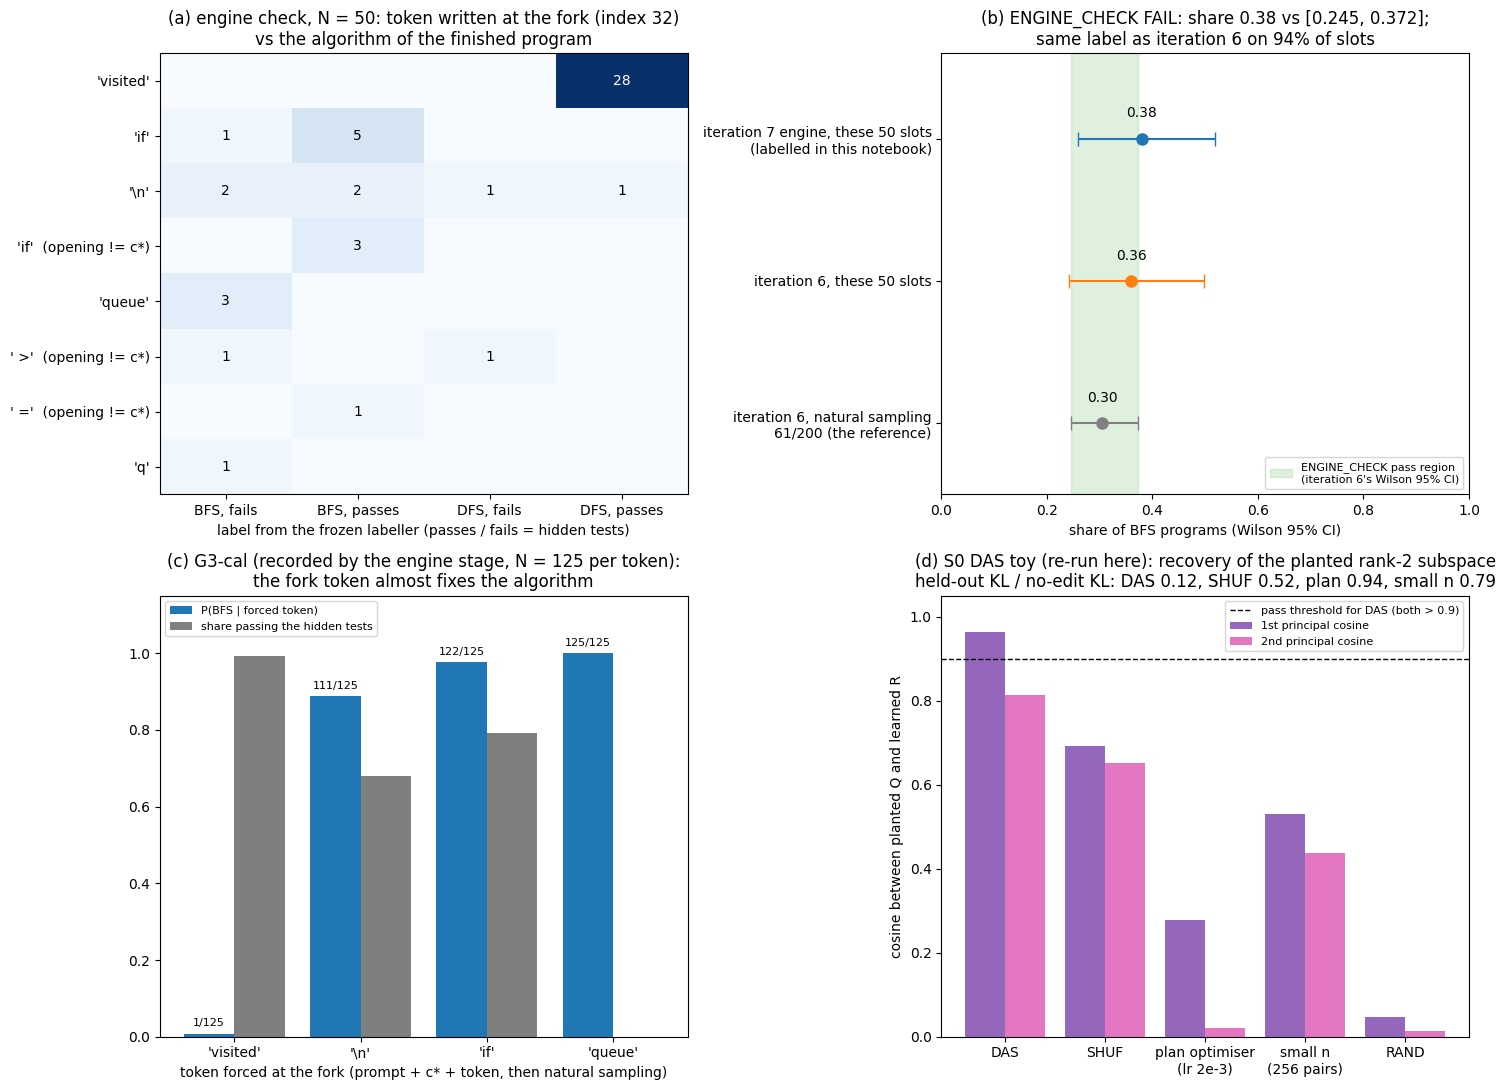

In [23]:
s0r = data["recorded"]["s0_tests"]
tok_ok = lambda d: bool(d["B_ok"] and d["D_ok"] and d["cstar_text_ok"])
summary = pd.DataFrame([
    ("S0 inputs: vendored files with a sha256 mismatch", f"{res['inputs_manifest']['n_mismatch']} of {res['inputs_manifest']['n_files']}",
     f"{s0r['inputs_manifest']['n_mismatch']} of {s0r['inputs_manifest']['n_files']}"),
    ("S0 reference programs labelled correctly", f"{res['labeller_references']['n_ok']}/{res['labeller_references']['n']}",
     f"{s0r['labeller_references']['n_ok']}/{s0r['labeller_references']['n']}"),
    ("S0 wrong programs rejected by the hidden tests", f"{res['checker_mutants']['n_rejected']}/{res['checker_mutants']['n']}",
     f"{s0r['checker_mutants']['n_rejected']}/{s0r['checker_mutants']['n']}"),
    ("S0 fork token ids and c* decode as expected", tok_ok(res["token_ids"]), tok_ok(s0r["token_ids"])),
    ("S0 CRN streams bit-identical", res["crn_identical"], s0r["crn_identical"]),
    ("S0 DAS toy: principal cosines of DAS", str(np.round(res["das_toy"]["das"]["principal_cosines"], 4).tolist()),
     str(np.round(data["recorded"]["das_toy"]["das"]["principal_cosines"], 4).tolist())),
    ("S0 DAS toy passes its threshold", res["das_toy"]["pass"], data["recorded"]["das_toy"]["pass"]),
    ("S0 batch shape B_CRN (rule on the recorded timings)", res["batch_time_test"]["chosen_B"], s0r["batch_time_test"]["chosen_B"]),
    ("S0 commitment #0: same design, hash chain verifies", design == data["recorded"]["commit0"]["design"] and verify_chain()["ok"], True),
    ("label: rows identical to the run's label rows", f"{int(cmp_df['same as the run'].sum())}/{len(cmp_df)}", "(reference)"),
    ("engine check: BFS programs / N", f"{ec['bfs']}/{ec['n']}", f"{rec_ec['bfs']}/{rec_ec['n']}"),
    ("engine check: correct BFS programs", ec["correct_bfs"], rec_ec["correct_bfs"]),
    ("engine check: same label as iteration 6 (per slot)", round(ec["per_slot_label_agreement"], 2), round(rec_ec["per_slot_label_agreement"], 2)),
    ("engine check: byte-identical to iteration 6's program", round(ec["identical_program_share"], 2), round(rec_ec["identical_program_share"], 2)),
    ("ENGINE_CHECK decision (pass?)", ec["pass"], rec_ec["pass"]),
], columns=["check", "this notebook", "recorded by the run"])
display(summary)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
# ---- (a) token at the fork vs the algorithm of the finished program
lab_rows = merged("raw_engine.jsonl")
cs_ids = cstar()
fork_name = [repr(tok.decode([r["token_ids"][FORK_INDEX]])) + ("" if r["token_ids"][:FORK_INDEX] == cs_ids else "  (opening != c*)")
             for r in lab_rows]
outcome = [r["label"].upper() + (", passes" if r["passed"] else ", fails") for r in lab_rows]
ft = pd.crosstab(pd.Series(fork_name, name="token at index 32"), pd.Series(outcome, name="program"))
ft = ft.loc[ft.sum(1).sort_values(ascending=False).index]
ax = axes[0, 0]
ax.imshow(ft.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(ft.shape[1]), ft.columns)
ax.set_yticks(range(ft.shape[0]), ft.index)
for i in range(ft.shape[0]):
    for j in range(ft.shape[1]):
        if ft.values[i, j]:
            ax.text(j, i, int(ft.values[i, j]), ha="center", va="center",
                    color="white" if ft.values[i, j] > ft.values.max() / 2 else "black")
ax.set_xlabel("label from the frozen labeller (passes / fails = hidden tests)")
ax.set_title(f"(a) engine check, N = {len(lab_rows)}: token written at the fork (index 32)\n"
             "vs the algorithm of the finished program")

# ---- (b) BFS share and Wilson CIs against iteration 6
ax = axes[0, 1]
k6 = round(ec["iter6_share_on_same_50_slots"] * ec["n"])
pts = [("iteration 6, natural sampling\n61/200 (the reference)", I6_NATURAL["k"] / I6_NATURAL["n"], I6_NATURAL["ci95"]),
       (f"iteration 6, these {ec['n']} slots", k6 / max(ec["n"], 1), wilson_ci(k6, ec["n"])),
       (f"iteration 7 engine, these {ec['n']} slots\n(labelled in this notebook)", ec["share"], ec["wilson95"])]
lo, hi = I6_NATURAL["ci95"]
ax.axvspan(lo, hi, color="tab:green", alpha=0.15, label="ENGINE_CHECK pass region\n(iteration 6's Wilson 95% CI)")
for i, (name, s, (l, h)) in enumerate(pts):
    ax.errorbar(s, i, xerr=[[s - l], [h - s]], fmt="o", color=["gray", "tab:orange", "tab:blue"][i], capsize=5, ms=8)
    ax.text(s, i + 0.15, f"{s:.2f}", ha="center")
ax.set_yticks(range(len(pts)), [q[0] for q in pts])
ax.set_xlim(0, 1)
ax.set_ylim(-0.5, len(pts) - 0.4)
ax.set_xlabel("share of BFS programs (Wilson 95% CI)")
ax.set_title(f"(b) ENGINE_CHECK {'PASS' if ec['pass'] else 'FAIL'}: share {ec['share']:.2f} vs [{lo}, {hi}];\n"
             f"same label as iteration 6 on {ec['per_slot_label_agreement']:.0%} of slots")
ax.legend(loc="lower right", fontsize=8)

# ---- (c) G3-cal (engine stage, recorded): P(BFS | forced fork token)
ax = axes[1, 0]
g = rec["g3_cal"]["by_token"]
x = np.arange(len(g))
ax.bar(x - 0.2, [v["p_bfs_of_all"] for v in g.values()], 0.4, label="P(BFS | forced token)", color="tab:blue")
ax.bar(x + 0.2, [v["n_pass"] / v["n"] for v in g.values()], 0.4, label="share passing the hidden tests", color="tab:gray")
for i, v in enumerate(g.values()):
    ax.text(i - 0.2, v["p_bfs_of_all"] + 0.02, f"{v['n_bfs']}/{v['n']}", ha="center", fontsize=8)
ax.set_xticks(x, [repr(tok.decode([int(t)])) for t in g])
ax.set_ylim(0, 1.15)
ax.set_xlabel("token forced at the fork (prompt + c* + token, then natural sampling)")
ax.set_title("(c) G3-cal (recorded by the engine stage, N = 125 per token):\n"
             "the fork token almost fixes the algorithm")
ax.legend(fontsize=8, loc="upper left")

# ---- (d) DAS toy (re-run here): recovery of the planted subspace
ax = axes[1, 1]
toy = res["das_toy"]
runs = [("DAS", toy["das"]["principal_cosines"]), ("SHUF", toy["shuf"]["principal_cosines"]),
        ("plan optimiser\n(lr 2e-3)", toy["plan_optimiser_lr2e-3"]["principal_cosines"]),
        ("small n\n(256 pairs)", toy["small_n_overfit"]["principal_cosines"]), ("RAND", toy["rand_principal_cosines"])]
x = np.arange(len(runs))
ax.bar(x - 0.2, [r[1][0] for r in runs], 0.4, label="1st principal cosine", color="tab:purple")
ax.bar(x + 0.2, [r[1][1] for r in runs], 0.4, label="2nd principal cosine", color="tab:pink")
ax.axhline(0.9, ls="--", color="k", lw=1, label="pass threshold for DAS (both > 0.9)")
ax.set_xticks(x, [r[0] for r in runs])
ax.set_ylim(0, 1.05)
ax.set_ylabel("cosine between planted Q and learned R")
kl = {nm: toy[k]["heldout_kl"] / toy[k]["heldout_kl_no_edit"]
      for nm, k in (("DAS", "das"), ("SHUF", "shuf"), ("plan", "plan_optimiser_lr2e-3"), ("small n", "small_n_overfit"))}
ax.set_title("(d) S0 DAS toy (re-run here): recovery of the planted rank-2 subspace\n"
             "held-out KL / no-edit KL: " + ", ".join(f"{k} {v:.2f}" for k, v in kl.items()))
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

## Notes

- **Sizes.** The configuration cell holds the sizes. At the original values (all 50 generations, 12 references, 5 mutants, the full DAS toy) the notebook re-derives the run's S0 tests, its label rows and its engine check. Smaller values give a quick smoke test.
- **The GPU stages.** `engine`, `g3a`/`g3b`, `yv`, `g1p`/`g1v` and `g2`/`g2r`/`g2d` need three things: the artifact's `src/` package, `google/gemma-3-4b-it` (with the licence accepted on Hugging Face) and a 16 GB GPU. Run them in the artifact folder as `.venv/bin/python method.py --stage <name>`, in the order of the stage list at the top of `method.py`. `novelty` also needs an OpenRouter key.
- **Outputs.** Everything this notebook writes (`results/s0_tests.json`, `predictions/commit0.json`, `commitments.log`, `data/labels.jsonl`, `results/engine_check.json`, `logs/`) is under `RUN_DIR`, a temporary folder.